# Session 5 · Classical medical image processing in Python

This notebook accompanies the slides. Every example works on **NIfTI (`.nii.gz`) images**.

| Part | Topic | Main tools |
|---|---|---|
| 0 | Setup and data | `nibabel`, `SimpleITK` |
| 1 | Loading NIfTI and understanding the header | `nibabel`, `SimpleITK` |
| 2 | Intensity normalisation | `numpy` |
| 3 | Resampling to isotropic spacing | `SimpleITK` |
| 4 | Filtering: Gaussian, median, edges | `scipy.ndimage`, `skimage` |
| 5 | Thresholding with Otsu | `skimage.filters` |
| 6 | Morphological operations | `scipy.ndimage`, `skimage.morphology` |
| 7 | Connected components, volumes and Dice | `skimage.measure` |
| 8 | Registration basics (demo) | `SimpleITK` |
| 9 | Exercises | |

**Data.** By default the notebook generates a small synthetic abdominal CT phantom (with a spleen label) and saves it as NIfTI, so it runs anywhere without downloads. To use real data, download **Task09_Spleen** from the Medical Segmentation Decathlon (medicaldecathlon.com) and set the two paths in Part 0. All code works the same on both.

## 0 · Setup and data
In Google Colab, uncomment the `pip` line first.

In [12]:
# !pip install nibabel SimpleITK scikit-image

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import SimpleITK as sitk
from scipy import ndimage
from skimage import filters, morphology, measure, feature

plt.rcParams["figure.dpi"] = 100
print("nibabel", nib.__version__, "| SimpleITK", sitk.__version__)

nibabel 5.2.1 | SimpleITK 2.3.1


In [13]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# Option A: real data from the Medical Segmentation Decathlon (Task09_Spleen)
# CT_PATH = Path("Task09_Spleen/imagesTr/spleen_10.nii.gz")
# LABEL_PATH = Path("Task09_Spleen/labelsTr/spleen_10.nii.gz")

# Option B (default): a synthetic phantom generated in the next cell
CT_PATH = DATA_DIR / "phantom_ct.nii.gz"
LABEL_PATH = DATA_DIR / "phantom_spleen.nii.gz"

### A synthetic abdominal CT phantom
Values are in Hounsfield units (HU): air −1000, fat −100, soft tissue 40, liver 60, contrast-enhanced spleen 110, bone 700. Slices are thick (0.8 × 0.8 × 5 mm), like a typical clinical CT, and Gaussian noise is added.

In [14]:
def make_phantom(ct_path, label_path, shape=(192, 192, 48), spacing=(0.8, 0.8, 5.0), seed=42):
    rng = np.random.default_rng(seed)
    # physical coordinates (mm) of every voxel centre
    x, y, z = np.meshgrid(*[np.arange(n) * s for n, s in zip(shape, spacing)], indexing="ij")
    cx, cy, cz = [n * s / 2 for n, s in zip(shape, spacing)]

    def ellipsoid(centre, radii):
        return sum(((c - c0) / r) ** 2 for c, c0, r in zip((x, y, z), centre, radii)) <= 1

    ct = np.full(shape, -1000.0)                                    # air
    ct[ellipsoid((cx, cy, cz), (70, 55, 1e4))] = -100               # fat layer (long cylinder)
    ct[ellipsoid((cx, cy, cz), (64, 49, 1e4))] = 40                 # soft tissue
    ct[ellipsoid((cx + 25, cy - 5, cz), (30, 28, 70))] = 60         # liver (patient's right, +x in RAS)
    spleen = ellipsoid((cx - 38, cy + 5, cz), (14, 20, 45))       # patient's left
    ct[spleen] = 110                                                # spleen (enhanced)
    ct[ellipsoid((cx - 28, cy - 30, cz), (5, 5, 5))] = 130          # small vessel near the spleen
    ct[ellipsoid((cx-38, cy - 20, cz), (7, 5, 9))] = 130 
    ct[ellipsoid((cx, cy - 35, cz), (12, 12, 1e4))] = 700           # spine (posterior, -y)

    ct = ndimage.gaussian_filter(ct, sigma=(1.0, 1.0, 0.3))          # partial-volume blur
    ct += rng.normal(0, 25, shape)                                   # scanner noise

    affine = np.diag([*spacing, 1.0])                                # voxel index -> mm (RAS)
    nib.save(nib.Nifti1Image(ct.astype(np.int16), affine), ct_path)
    nib.save(nib.Nifti1Image(spleen.astype(np.uint8), affine), label_path)

if  not CT_PATH.exists():
    make_phantom(CT_PATH, LABEL_PATH)
    print("Phantom written to", CT_PATH, "and", LABEL_PATH)
else:
    print("Using", CT_PATH)

Using data/phantom_ct.nii.gz


### A helper to view a 3D volume
`nibabel` returns arrays indexed as **(x, y, z)**. The helper shows axial, coronal and sagittal slices, corrects the aspect ratio using the voxel spacing, and can overlay a mask.

Display note: slices are rotated so anterior (axial) and superior (coronal, sagittal) are at the top. Left–right follows the array order, so for real scans check the orientation codes printed in Part 1; clinical viewers use the radiological convention (patient's right on the viewer's left).

In [15]:
def show_slices(vol, mask=None, spacing=(1, 1, 1), idx=None, title="", window=(-160, 240)):
    # Axial, coronal and sagittal views of an (x, y, z) volume, with an optional mask overlay.
    if idx is None:
        idx = ndimage.center_of_mass(mask) if mask is not None and mask.any() else np.array(vol.shape) / 2
        idx = [int(i) for i in idx]
    sx, sy, sz = spacing[:3]
    views = [("Axial", np.s_[:, :, idx[2]], sy / sx),
             ("Coronal", np.s_[:, idx[1], :], sz / sx),
             ("Sagittal", np.s_[idx[0], :, :], sz / sy)]
    vmin, vmax = window if window is not None else np.percentile(vol, [1, 99])
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, sl, aspect) in zip(axes, views):
        ax.imshow(np.rot90(vol[sl]), cmap="gray", vmin=vmin, vmax=vmax, aspect=aspect)
        if mask is not None:
            m = np.rot90(mask[sl]).astype(float)
            ax.imshow(np.ma.masked_where(m == 0, m), cmap="autumn", alpha=0.5, aspect=aspect)
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

## 1 · Loading NIfTI and understanding the header
A NIfTI file holds the voxel array **and** a header describing the geometry: voxel spacing and the **affine**, which maps voxel indices to millimetres in the scanner (patient) coordinate system.

In [16]:
img = nib.load(CT_PATH)
print("Shape:          ", img.shape)
print("Data type:      ", img.header.get_data_dtype())
print("Spacing (mm):   ", img.header.get_zooms())
print("Orientation:    ", nib.aff2axcodes(img.affine))
print("Affine:\n", img.affine)

ct = img.get_fdata(dtype=np.float32)                       # (x, y, z) array in HU
lab = np.asarray(nib.load(LABEL_PATH).dataobj).astype(np.uint8)
spacing = img.header.get_zooms()[:3]
print(f"\nHU range: {ct.min():.0f} to {ct.max():.0f}")

Shape:           (192, 192, 48)
Data type:       int16
Spacing (mm):    (0.8, 0.8, 5.0)
Orientation:     ('R', 'A', 'S')
Affine:
 [[0.80000001 0.         0.         0.        ]
 [0.         0.80000001 0.         0.        ]
 [0.         0.         5.         0.        ]
 [0.         0.         0.         1.        ]]

HU range: -1120 to 807


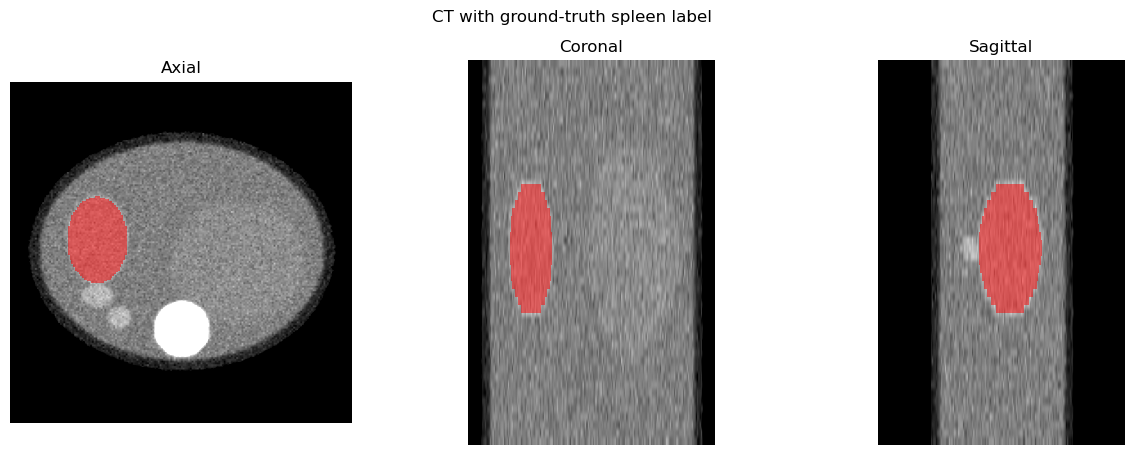

In [17]:
show_slices(ct, lab, spacing, title="CT with ground-truth spleen label")

The same file with **SimpleITK**. Note the axis order: SimpleITK *images* are (x, y, z), but `GetArrayFromImage` returns a NumPy array ordered **(z, y, x)**. Transposing gives back the `nibabel` array.

In [18]:
ct_sitk = sitk.ReadImage(str(CT_PATH))
print("Size (x, y, z):   ", ct_sitk.GetSize())
print("Spacing (x, y, z):", ct_sitk.GetSpacing())
print("Origin:           ", ct_sitk.GetOrigin())

arr_zyx = sitk.GetArrayFromImage(ct_sitk)
print("NumPy shape (z, y, x):", arr_zyx.shape)
print("Same voxels as nibabel after transposing:", np.allclose(arr_zyx.transpose(2, 1, 0), ct))

def to_numpy(image):
    # SimpleITK image -> NumPy array in (x, y, z) order, matching nibabel.
    return sitk.GetArrayFromImage(image).transpose(2, 1, 0)

Size (x, y, z):    (192, 192, 48)
Spacing (x, y, z): (0.800000011920929, 0.800000011920929, 5.0)
Origin:            (0.0, 0.0, 0.0)
NumPy shape (z, y, x): (48, 192, 192)
Same voxels as nibabel after transposing: True


## 2 · Intensity normalisation
| Method | Formula | Use when |
|---|---|---|
| Clipping / windowing | keep values in [a, b] | CT (HU windows), removing outliers |
| Min–max | (x − min) / (max − min) | You need a fixed [0, 1] range |
| Percentile clipping | clip to 1st–99th percentile | Robust first step for MRI |
| Z-score | (x − μ) / σ | MRI; compute μ and σ on the **foreground** only |

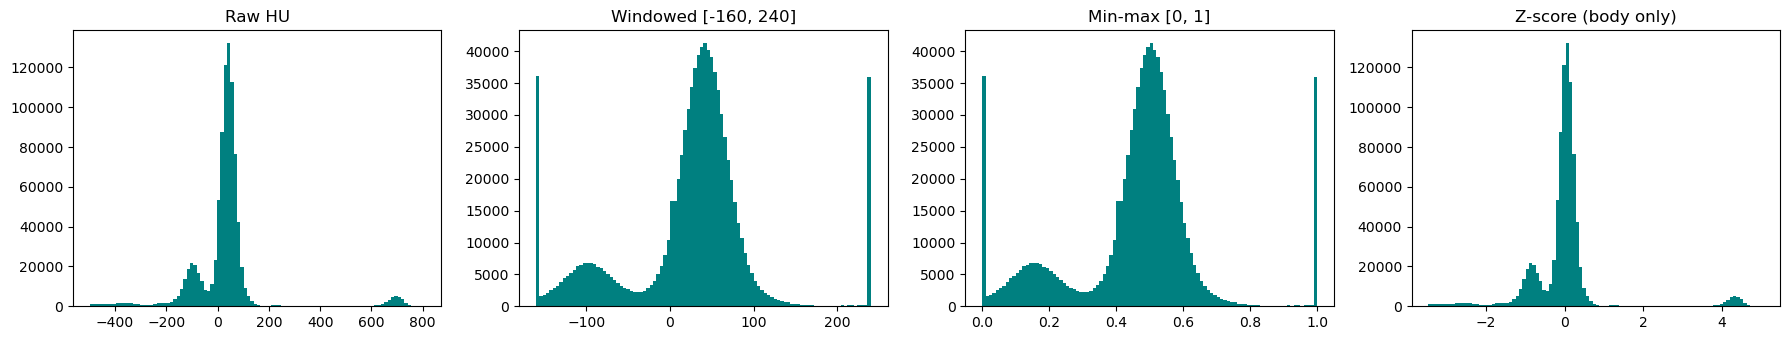

In [19]:
def window(img, lo, hi):
    return np.clip(img, lo, hi)

def minmax(img):
    return (img - img.min()) / (img.max() - img.min() + 1e-8)

def percentile_clip(img, p_lo=1, p_hi=99, mask=None):
    vals = img[mask > 0] if mask is not None else img
    lo, hi = np.percentile(vals, [p_lo, p_hi])
    return np.clip(img, lo, hi)

def zscore(img, mask=None):
    vals = img[mask > 0] if mask is not None else img
    return (img - vals.mean()) / (vals.std() + 1e-8)

body = ct > -500                                   # foreground: everything that is not air
ct_win = window(ct, -160, 240)                     # soft-tissue window
ct_01 = minmax(ct_win)
ct_pct = percentile_clip(ct, mask=body)
ct_z_all = zscore(ct)                              # statistics include the air
ct_z_body = zscore(ct, body)                       # statistics from the body only

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, data, t in zip(axes, [ct, ct_win, ct_01, ct_z_body],
                       ["Raw HU", "Windowed [-160, 240]", "Min-max [0, 1]", "Z-score (body only)"]):
    ax.hist(data[body].ravel(), bins=100, color="teal")
    ax.set_title(t)
plt.tight_layout()
plt.show()

In [20]:
# Why compute statistics on the foreground only?
print(f"Fraction of voxels that are air: {1 - body.mean():.0%}")
spleen_vals = lab > 0
print(f"Mean spleen z-score, stats from whole volume: {ct_z_all[spleen_vals].mean():.2f}")
print(f"Mean spleen z-score, stats from body only:    {ct_z_body[spleen_vals].mean():.2f}")
print("With the whole volume, the result depends on how much air is in the field of view.")

Fraction of voxels that are air: 49%
Mean spleen z-score, stats from whole volume: 1.09
Mean spleen z-score, stats from body only:    0.48
With the whole volume, the result depends on how much air is in the field of view.


## 3 · Resampling to isotropic spacing
Thick slices make voxels anisotropic, so filters and morphology act differently along z. We resample to **1.5 mm isotropic**.

* Images: **linear** (or B-spline) interpolation.
* Label masks: **nearest neighbour** only.

In [35]:
def resample(image, new_spacing=(1.5, 1.5, 1.5), is_mask=False, fill=0):
    old_sp, old_sz = image.GetSpacing(), image.GetSize()
    new_sz = [int(round(sz * sp / ns)) for sz, sp, ns in zip(old_sz, old_sp, new_spacing)]
    interp = sitk.sitkNearestNeighbor if is_mask else sitk.sitkLinear
    return sitk.Resample(image, new_sz, sitk.Transform(), interp, image.GetOrigin(),
                         new_spacing, image.GetDirection(), fill, image.GetPixelID())

ISO = (1.5, 1.5, 1.5)
lab_sitk = sitk.ReadImage(str(LABEL_PATH))

ct_iso_sitk = resample(sitk.Cast(ct_sitk, sitk.sitkFloat32), ISO, fill=-1024)   # pad with air, not water
lab_iso_sitk = resample(lab_sitk, ISO, is_mask=True)

print("Before:", ct_sitk.GetSize(), "voxels at", ct_sitk.GetSpacing(), "mm")
print("After: ", ct_iso_sitk.GetSize(), "voxels at", ct_iso_sitk.GetSpacing(), "mm")

Before: (192, 192, 48) voxels at (0.800000011920929, 0.800000011920929, 5.0) mm
After:  (102, 102, 160) voxels at (1.5, 1.5, 1.5) mm


In [36]:
# What goes wrong if a mask is resampled with linear interpolation?
lab_linear = to_numpy(resample(sitk.Cast(lab_sitk, sitk.sitkFloat32), ISO, is_mask=False))
lab_nearest = to_numpy(lab_iso_sitk)
print("Distinct values, nearest neighbour:", np.unique(lab_nearest))
print("Distinct values, linear:           ", len(np.unique(lab_linear)), "e.g.", np.unique(lab_linear)[1:6].round(2))

Distinct values, nearest neighbour: [0 1]
Distinct values, linear:            1165 e.g. [0. 0. 0. 0. 0.]


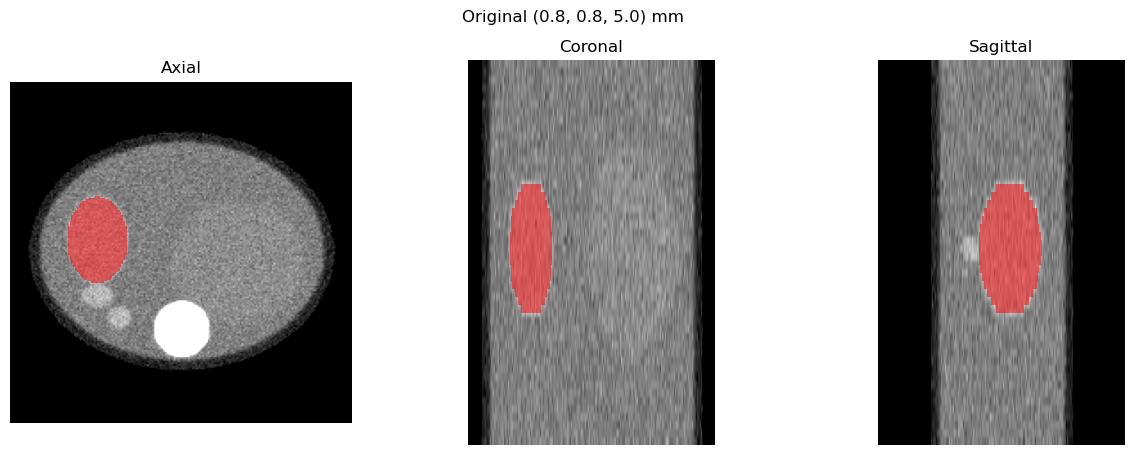

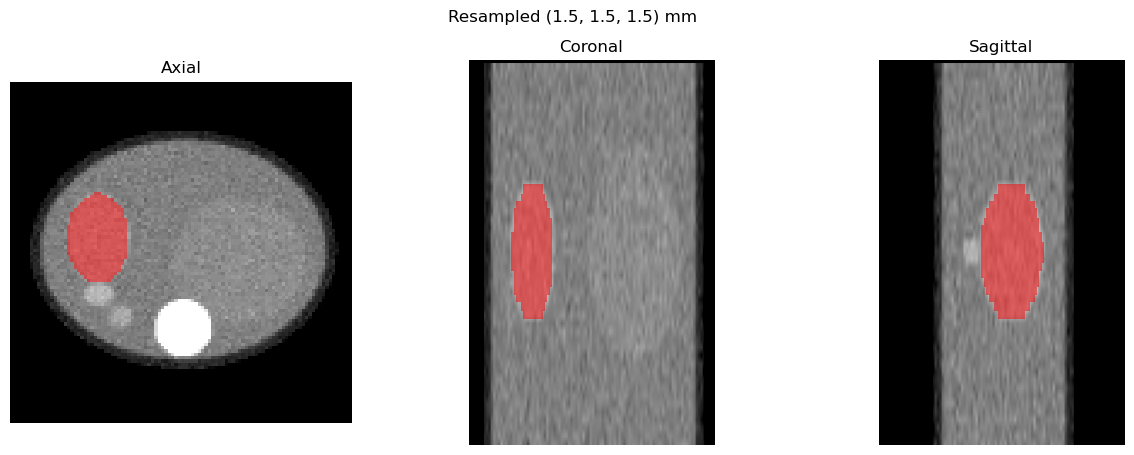

In [23]:
ct_iso = to_numpy(ct_iso_sitk).astype(np.float32)
lab_iso = to_numpy(lab_iso_sitk).astype(np.uint8)
iso_spacing = ct_iso_sitk.GetSpacing()

show_slices(ct, lab, spacing, title=f"Original {spacing} mm")
show_slices(ct_iso, lab_iso, iso_spacing, title=f"Resampled {iso_spacing} mm")

sitk.WriteImage(ct_iso_sitk, str(DATA_DIR / "ct_iso.nii.gz"))
sitk.WriteImage(lab_iso_sitk, str(DATA_DIR / "label_iso.nii.gz"))

> With `nibabel` only, `nibabel.processing.resample_to_output(img, voxel_sizes=(1.5, 1.5, 1.5), order=1)` does the same job (`order=0` for masks).

From here on we work with `ct_iso`, `lab_iso` and `iso_spacing`.

## 4 · Filtering
* **Gaussian**: weighted average, removes random noise, blurs edges. Controlled by σ (in voxels).
* **Median**: neighbourhood median, removes impulse (salt-and-pepper) noise and keeps edges.
* **Edges**: Sobel gives gradient magnitude; Canny gives thin edges (2D). Smooth first.

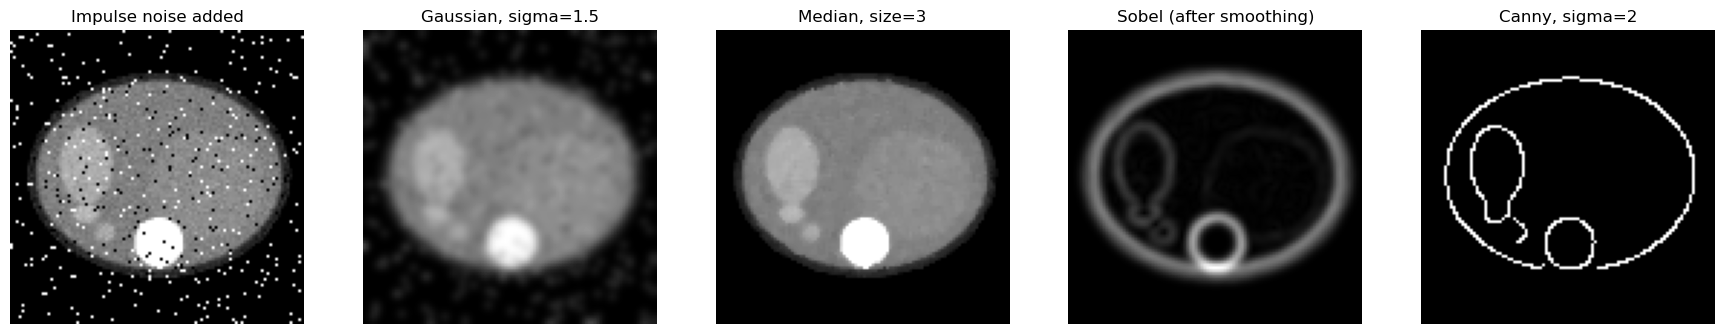

In [24]:
z = int(ndimage.center_of_mass(lab_iso)[2])          # axial slice through the spleen
sl = window(ct_iso[:, :, z], -160, 240)

# Add impulse noise to show the difference between Gaussian and median filters
rng = np.random.default_rng(0)
noisy = sl.copy()
r = rng.random(sl.shape)
noisy[r < 0.03] = -160
noisy[r > 0.97] = 240

gauss = ndimage.gaussian_filter(noisy, sigma=1.5)
med = ndimage.median_filter(noisy, size=3)
sob = filters.sobel(ndimage.gaussian_filter(sl, sigma=1.5))
can = feature.canny(minmax(sl), sigma=2)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, im, t in zip(axes, [noisy, gauss, med, sob, can],
                     ["Impulse noise added", "Gaussian, sigma=1.5", "Median, size=3", "Sobel (after smoothing)", "Canny, sigma=2"]):
    ax.imshow(np.rot90(im), cmap="gray")
    ax.set_title(t)
    ax.axis("off")
plt.show()

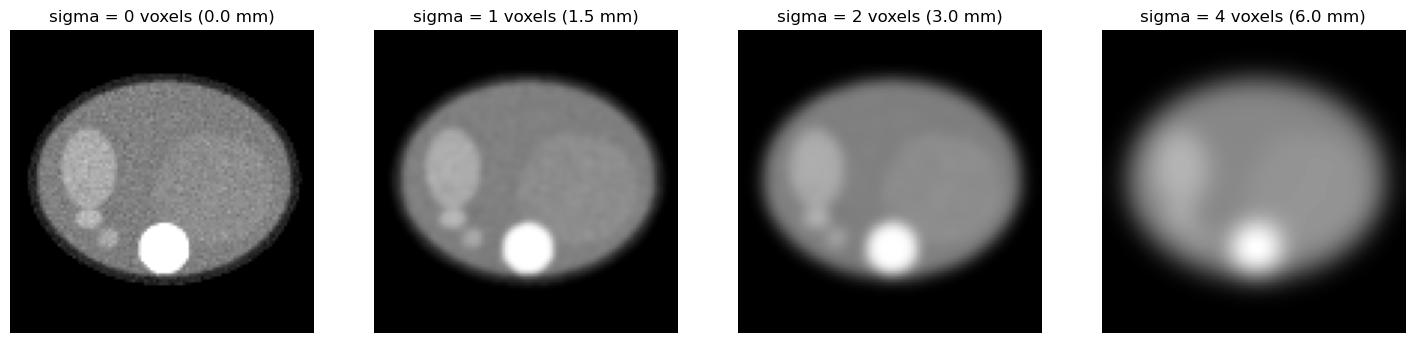

In [25]:
# Effect of sigma
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, s in zip(axes, [0, 1, 2, 4]):
    ax.imshow(np.rot90(ndimage.gaussian_filter(sl, sigma=s)), cmap="gray")
    ax.set_title(f"sigma = {s} voxels ({s * iso_spacing[0]:.1f} mm)")
    ax.axis("off")
plt.show()

# 3D smoothing of the whole volume, used in the next steps
ct_smooth = ndimage.gaussian_filter(ct_iso, sigma=1.0)

## 5 · Thresholding with Otsu
Otsu chooses the threshold that best separates **two** intensity classes in the histogram. On a whole CT the two biggest classes are air and body, so a global threshold finds the body, not the spleen.

Global Otsu threshold: -479 HU


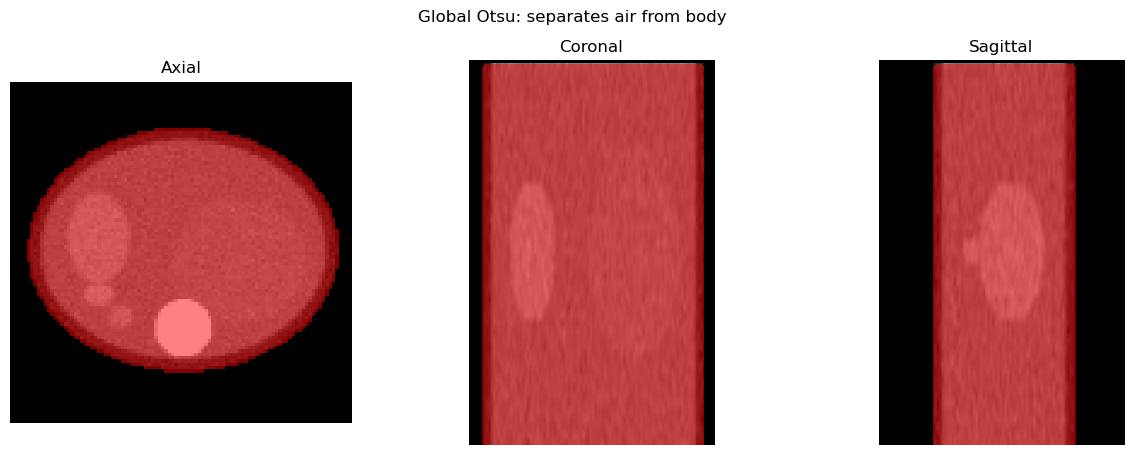

In [37]:
t_global = filters.threshold_otsu(ct_smooth)
mask_global = ct_smooth > t_global
print(f"Global Otsu threshold: {t_global:.0f} HU")
show_slices(ct_iso, mask_global, iso_spacing, idx=[int(i) for i in ndimage.center_of_mass(lab_iso)],
            title="Global Otsu: separates air from body")

To segment the spleen we restrict Otsu to a **region of interest (ROI)** and to soft-tissue values. In practice the ROI comes from a clinician's rough box or a coarse detector; here we simulate it as a box around the label with a 20 mm margin.

Otsu threshold inside ROI: 70 HU


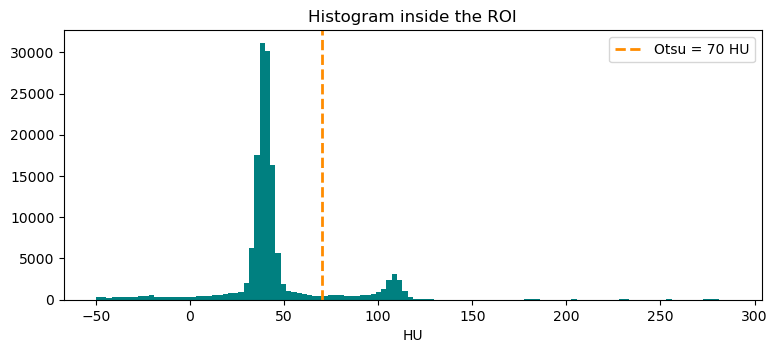

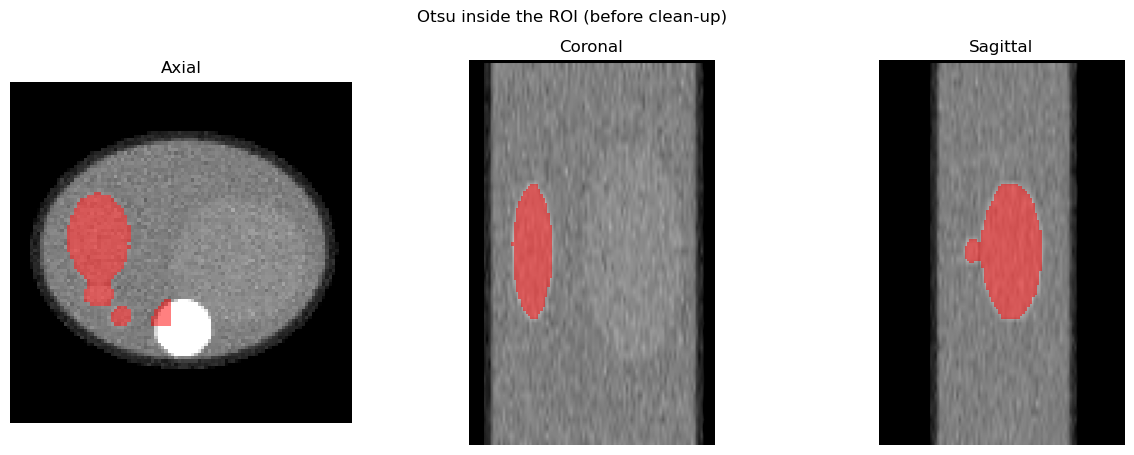

In [27]:
coords = np.argwhere(lab_iso)
margin = int(round(20 / iso_spacing[0]))
lo = np.maximum(coords.min(0) - margin, 0)
hi = np.minimum(coords.max(0) + margin + 1, lab_iso.shape)
roi = np.zeros(lab_iso.shape, bool)
roi[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]] = True

soft = roi & (ct_smooth > -50) & (ct_smooth < 300)        # ignore air, fat and bone
t_roi = filters.threshold_otsu(ct_smooth[soft])
mask = roi & (ct_smooth > t_roi)
print(f"Otsu threshold inside ROI: {t_roi:.0f} HU")

plt.figure(figsize=(9, 3.5))
plt.hist(ct_smooth[soft].ravel(), bins=120, color="teal")
plt.axvline(t_roi, color="darkorange", ls="--", lw=2, label=f"Otsu = {t_roi:.0f} HU")
plt.xlabel("HU")
plt.legend()
plt.title("Histogram inside the ROI")
plt.show()

show_slices(ct_iso, mask, iso_spacing, title="Otsu inside the ROI (before clean-up)")

In [28]:
# More than two classes: multi-Otsu
ts = filters.threshold_multiotsu(ct_smooth[ct_smooth > -500], classes=3)
print("Multi-Otsu thresholds for 3 classes inside the body:", ts.round(0))

Multi-Otsu thresholds for 3 classes inside the body: [-124.  321.]


## 6 · Morphological operations
| Operation | Effect | Typical use |
|---|---|---|
| Erosion | shrinks objects, breaks thin bridges | separate touching structures |
| Dilation | grows objects, fills narrow gaps | add a safety margin |
| Opening (erode → dilate) | removes small specks | clean a noisy threshold |
| Closing (dilate → erode) | fills small holes and gaps | smooth boundaries |

First a 2D demonstration on one slice of the thresholded mask:

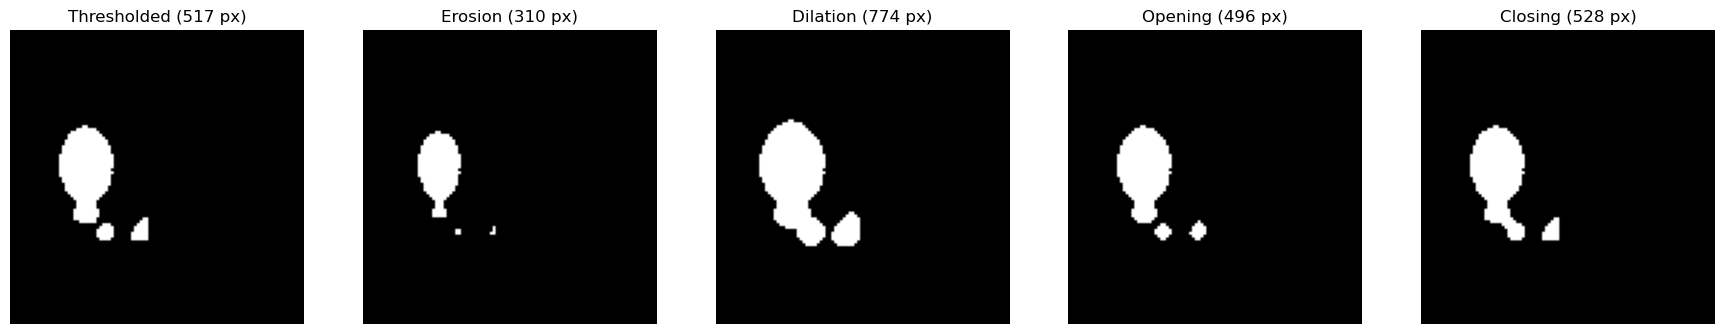

In [29]:
m2d = mask[:, :, z]
disk = morphology.disk(2)
# print(disk)
ops = {
    "Thresholded": m2d,
    "Erosion": ndimage.binary_erosion(m2d, structure=disk),
    "Dilation": ndimage.binary_dilation(m2d, structure=disk),
    "Opening": ndimage.binary_opening(m2d, structure=disk),
    "Closing": ndimage.binary_closing(m2d, structure=disk),
}
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (name, m) in zip(axes, ops.items()):
    ax.imshow(np.rot90(m), cmap="gray")
    ax.set_title(f"{name} ({m.sum()} px)")
    ax.axis("off")
plt.show()

Now clean the 3D mask. A **ball** of radius 2 voxels (3 mm) is the 3D structuring element.

thresholded             19548 voxels
after opening           18358 voxels
after closing           18384 voxels
after hole filling      18384 voxels


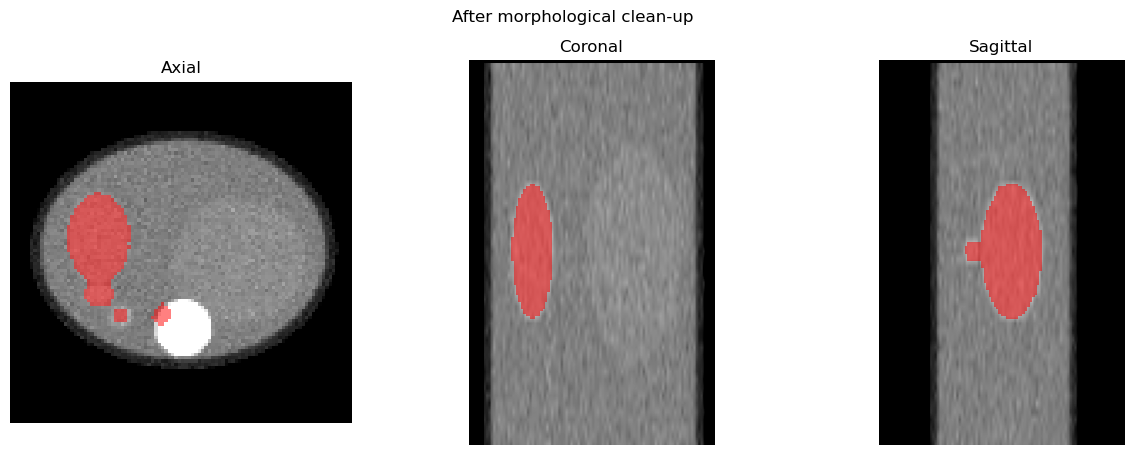

In [30]:
ball = morphology.ball(2)
mask_open = ndimage.binary_opening(mask, structure=ball)          # remove specks
mask_close = ndimage.binary_closing(mask_open, structure=ball)    # close small gaps
mask_clean = ndimage.binary_fill_holes(mask_close)                # fill enclosed cavities

for name, m in [("thresholded", mask), ("after opening", mask_open),
                ("after closing", mask_close), ("after hole filling", mask_clean)]:
    print(f"{name:20s} {m.sum():8d} voxels")

show_slices(ct_iso, mask_clean, iso_spacing, title="After morphological clean-up")

## 7 · Connected components, volumes and evaluation
1. **Label** each separate blob, 2. **measure** it with `regionprops`, 3. **keep** the largest, 4. **convert** voxel counts to mL using the spacing.

In [31]:
labels = measure.label(mask_clean, connectivity=3)           # 26-connectivity in 3D
props = sorted(measure.regionprops(labels), key=lambda p: p.area, reverse=True)   # area = voxel count in 3D
voxel_ml = np.prod(iso_spacing) / 1000                       # mm^3 -> mL

print(f"{len(props)} components found")
for p in props[:5]:
    centroid_mm = np.array(p.centroid) * iso_spacing
    print(f"label {p.label:3d}: {int(p.area):7d} voxels = {p.area * voxel_ml:6.1f} mL, centroid (mm) {centroid_mm.round(0)}")

seg = labels == props[0].label                               # keep the largest component

2 components found
label   1:   16288 voxels =   55.0 mL, centroid (mm) [ 39.  81. 120.]
label   2:    2096 voxels =    7.1 mL, centroid (mm) [ 67.  48. 120.]


In [32]:
def dice(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2 * (a & b).sum() / (a.sum() + b.sum())

truth = lab_iso > 0
for name, m in [("Otsu in ROI", mask), ("+ morphology", mask_clean), ("+ largest component", seg)]:
    print(f"{name:22s} Dice = {dice(m, truth):.3f}")

print(f"\nPredicted spleen volume:    {seg.sum() * voxel_ml:.1f} mL")
print(f"Ground-truth spleen volume: {truth.sum() * voxel_ml:.1f} mL")

Otsu in ROI            Dice = 0.870
+ morphology           Dice = 0.896
+ largest component    Dice = 0.955

Predicted spleen volume:    55.0 mL
Ground-truth spleen volume: 52.3 mL


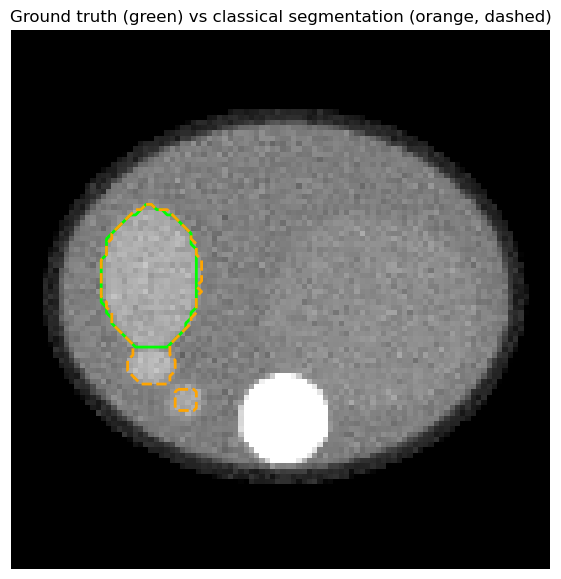

In [33]:
# Compare contours on one axial slice
plt.figure(figsize=(7, 7))
plt.imshow(np.rot90(window(ct_iso[:, :, z], -160, 240)), cmap="gray")
plt.contour(np.rot90(truth[:, :, z]), levels=[0.5], colors="lime", linewidths=2)
plt.contour(np.rot90(seg[:, :, z]), levels=[0.5], colors="orange", linewidths=2, linestyles="--")
plt.title("Ground truth (green) vs classical segmentation (orange, dashed)")
plt.axis("off")
plt.show()

Save the result as NIfTI **with the same geometry** as the image, so it opens correctly in ITK-SNAP or 3D Slicer.

In [34]:
seg_img = sitk.GetImageFromArray(seg.astype(np.uint8).transpose(2, 1, 0))   # back to (z, y, x)
seg_img.CopyInformation(ct_iso_sitk)                                        # spacing, origin, direction
sitk.WriteImage(seg_img, str(DATA_DIR / "spleen_seg_classical.nii.gz"))

# The same with nibabel, reusing the affine of the resampled image
nib_iso = nib.load(DATA_DIR / "ct_iso.nii.gz")
nib.save(nib.Nifti1Image(seg.astype(np.uint8), nib_iso.affine), DATA_DIR / "spleen_seg_classical_nib.nii.gz")
print("Saved segmentation to", DATA_DIR)

Saved segmentation to data


## 8 · Exercises
1. **Real data.** Switch to a Medical Segmentation Decathlon spleen case (Part 0) and run the whole notebook. Which step needs re-tuning?
2. **Spacing.** Repeat the segmentation with 1.0 mm and 3.0 mm isotropic spacing. How do Dice and run time change?
3. **Filters.** Replace the Gaussian (σ = 1) before thresholding with a median filter. Does Dice improve?
4. **Morphology.** Try ball radii 1, 2 and 4 for opening and closing. Plot Dice against radius.
5. **No ROI.** Run Otsu inside the whole body without the ROI. Why does it fail, and what does that tell you about classical vs learned segmentation?
6. **Pitfalls.** Deliberately (a) resample the label with linear interpolation and (b) report volume in voxels. Quantify how wrong each result is.